# 01 – Análise exploratória: calor, idosos e cidade em Santa Maria/RS

**Projeto Refúgio – Global Solution 2026.2 (CitizenTech)**

Este caderno responde a três perguntas com dados públicos e reais:

1. **O calor extremo está aumentando em Santa Maria?** (clima, 1991–2025)
2. **O calor faz mal aos idosos da cidade?** (DATASUS × clima, 2020–2025)
3. **Onde, dentro da cidade, o calor e os idosos se encontram?** (Censo 2022 × satélite Landsat)

> Para reproduzir: rode antes os scripts de `src/data/` (veja o README). Todas as fontes estão em `data/README.md`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # permite importar o pacote src
import pandas as pd, numpy as np, geopandas as gpd, matplotlib.pyplot as plt
from src import config as C
from src.analise import figuras  # aplica o estilo visual padrão do projeto
pd.set_option("display.precision", 2)
clima = pd.read_csv(C.PROCESSED / "clima_diario.csv", parse_dates=["data"])
saude = pd.read_csv(C.PROCESSED / "saude_diaria.csv", parse_dates=["data"])
setores = gpd.read_file(C.PROCESSED / "setores_santa_maria.gpkg")
print(f"clima: {len(clima):,} dias | saúde: {len(saude):,} linhas | setores: {len(setores)}")

clima: 12,843 dias | saúde: 4,383 linhas | setores: 406


## 1. Clima

### 1.1 Qualidade: a reanálise ERA5 representa bem a estação?

n = 1794 dias | viés médio = +0.34 °C | erro absoluto médio = 0.86 °C | r = 0.983


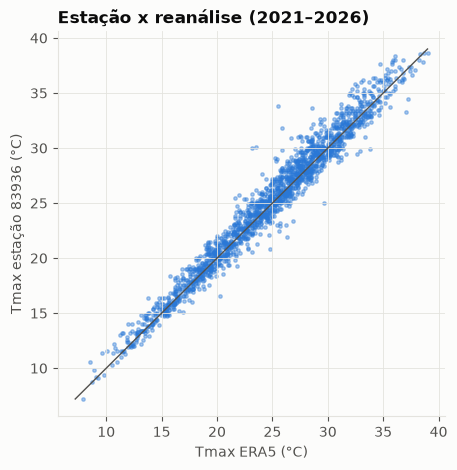

In [2]:
comum = clima.dropna(subset=["tmax_estacao", "tmax_era5"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(comum.tmax_era5, comum.tmax_estacao, s=6, alpha=.4, color=figuras.AZUL)
lim = [comum[["tmax_era5","tmax_estacao"]].min().min(), comum[["tmax_era5","tmax_estacao"]].max().max()]
ax.plot(lim, lim, color=figuras.TEXTO_2, lw=1)
ax.set_xlabel("Tmax ERA5 (°C)"); ax.set_ylabel("Tmax estação 83936 (°C)")
ax.set_title("Estação x reanálise (2021–2026)")
erro = comum.tmax_estacao - comum.tmax_era5
print(f"n = {len(comum)} dias | viés médio = {erro.mean():+.2f} °C | erro absoluto médio = {erro.abs().mean():.2f} °C | r = {comum.tmax_estacao.corr(comum.tmax_era5):.3f}")

A correlação é muito alta (r ≈ 0,98), com um viés pequeno que corrigimos somando a diferença média. A reanálise subestima um pouco os picos (resolução de ~25 km). Por isso, as **tendências** usam a série homogênea ERA5 corrigida, e a **análise de saúde** usa a estação sempre que existe.

### 1.2 Tendência: dias com máxima ≥ 35 °C

salvo docs/img/dias_35C_por_ano.png


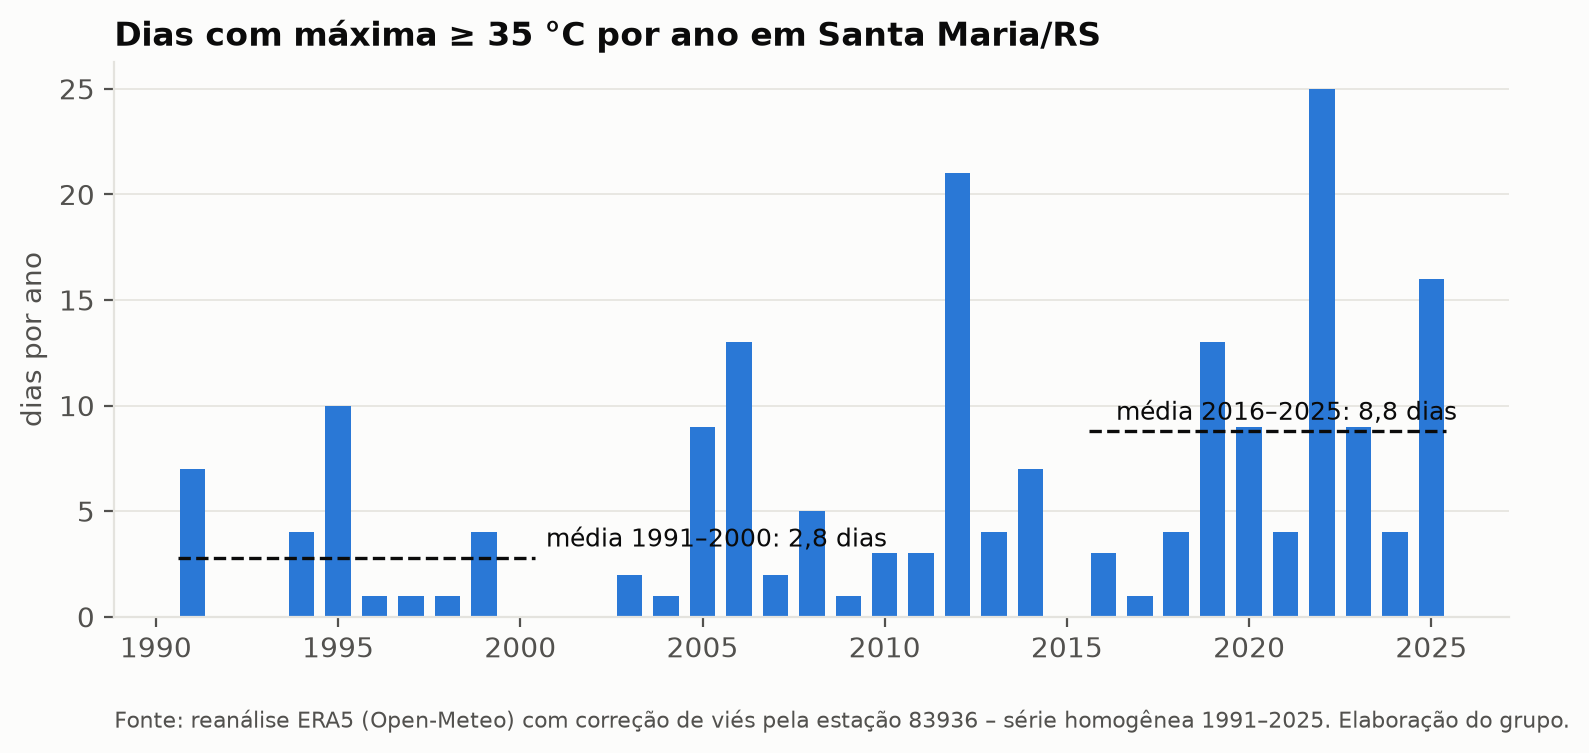

In [3]:
from IPython.display import Image
figuras.dias_de_calor_por_ano()
Image(C.DOCS_IMG / "dias_35C_por_ano.png")

In [4]:
anual = (clima.tmax_era5_corrigido >= 35).groupby(clima.data.dt.year).sum().loc[1991:2025]
decadas = anual.groupby((anual.index - 1991) // 10 * 10 + 1991).mean()
decadas.index = [f"{d}–{min(d+9, 2025)}" for d in decadas.index]
display(decadas.rename("dias ≥ 35 °C por ano (média)").to_frame())
verao = clima[clima.data.dt.month.isin([12, 1, 2])].dropna(subset=["tmax_era5_corrigido"])
tend = np.polyfit(verao.data.dt.year, verao.tmax_era5_corrigido, 1)[0] * 10
print(f"Tendência da Tmax de verão: {tend:+.2f} °C por década")

,dias ≥ 35 °C por ano (média)
1991–2000,2.8
2001–2010,3.6
2011–2020,6.5
2021–2025,11.6


Tendência da Tmax de verão: +0.53 °C por década


## 2. O calor faz mal aos idosos de Santa Maria?

Método: razão observado/esperado nos dias quentes, em que o *esperado* é a média dos dias do mesmo mês/ano e do mesmo dia da semana (controla sazonalidade, tendência e fim de semana). Detalhes em `src/analise/calor_saude.py`.

In [5]:
from src.analise.calor_saude import tabela_resultados
res = tabela_resultados()
res[["rotulo", "dias", "observado", "esperado", "excesso", "rr", "ic_inf", "ic_sup"]]

,rotulo,dias,observado,esperado,excesso,rr,ic_inf,ic_sup
0,Óbitos de idosos (todas as causas),65,396,347.15,48.85,1.14,1.04,1.24
1,Óbitos de idosos (causas sensíveis ao calor),65,163,141.80,21.20,1.15,0.99,1.31
2,Internações de idosos (todas as causas),71,823,862.30,-39.30,0.95,0.90,1.01
3,Internações de idosos (causas sensíveis ao calor),71,278,275.00,3.00,1.01,0.91,1.11


salvo docs/img/calor_saude_idosos.png


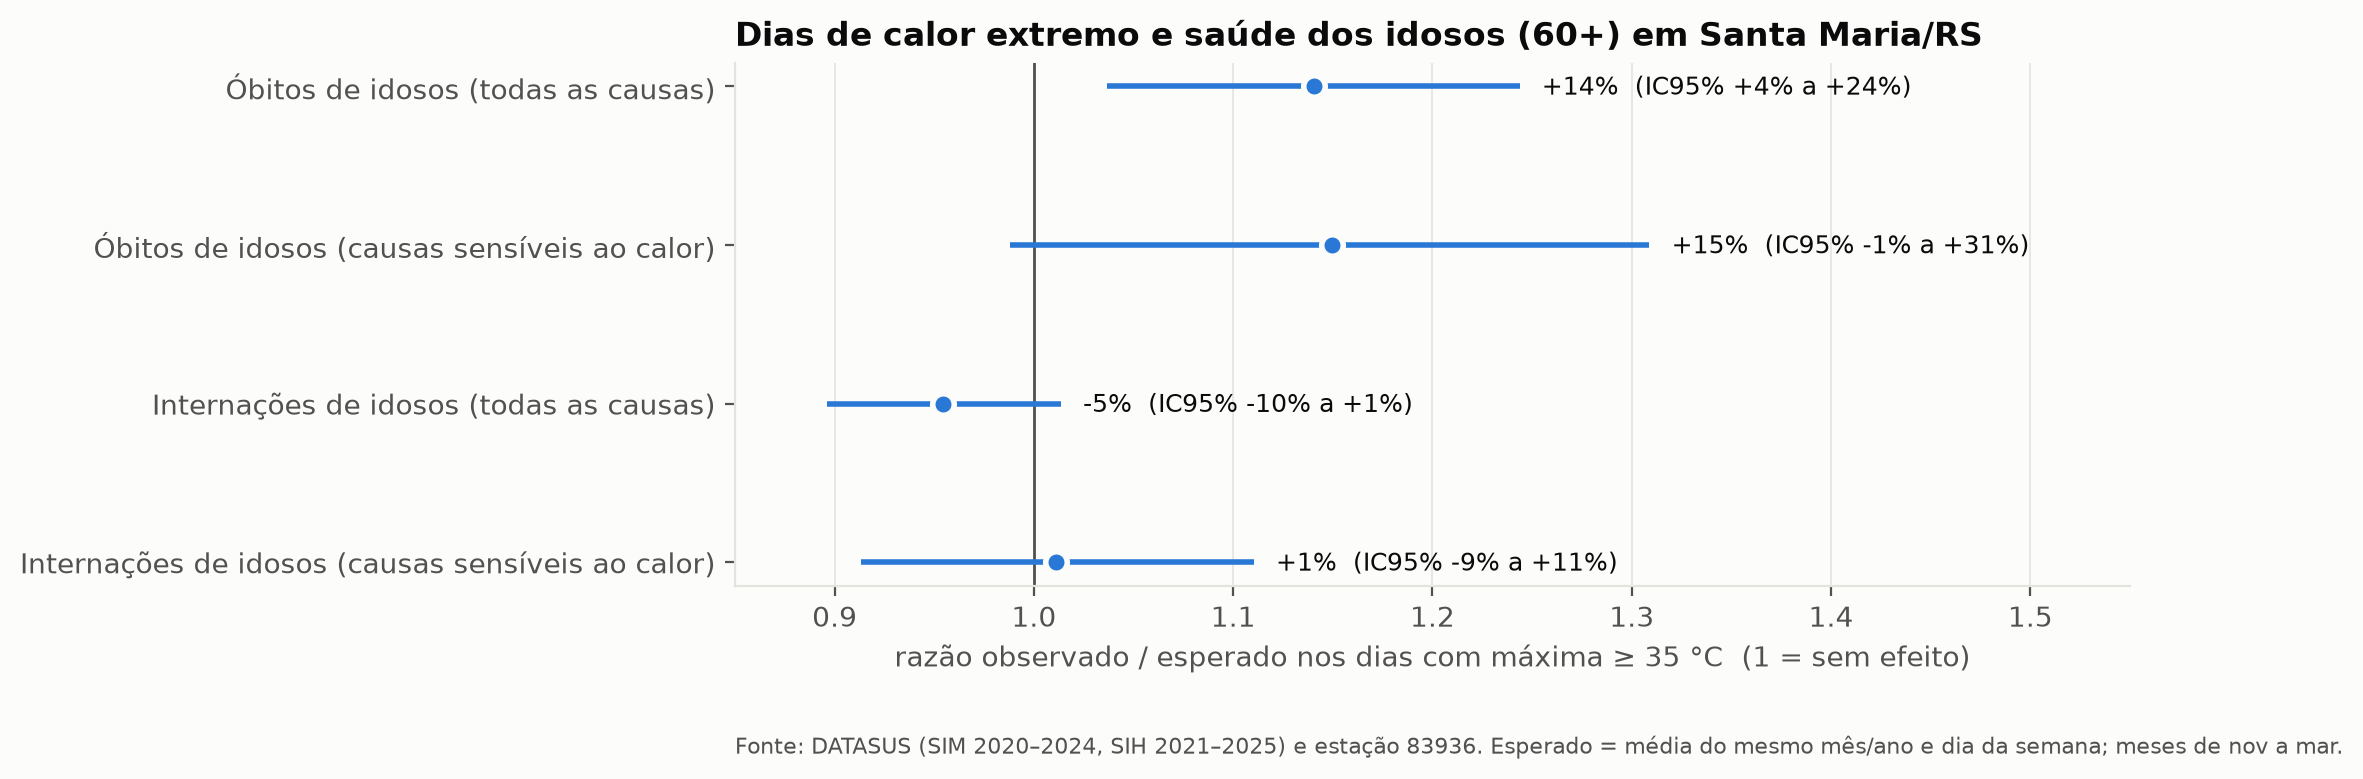

In [6]:
figuras.calor_e_saude()
Image(C.DOCS_IMG / "calor_saude_idosos.png")

**Leitura:**
- O efeito cresce com a temperatura (dose-resposta, seção 2.1): a razão fica perto de 1 abaixo de 31 °C e sobe para cerca de 1,08 entre 33 e 35 °C e para 1,13 acima de 35 °C.
- Nos dias com 35 °C ou mais, os **óbitos de idosos** ficam cerca de **14% acima do esperado**, e o intervalo de confiança não inclui 1.
- As **internações não aumentam**. Hipóteses: parte das internações é eletiva e é adiada em dias muito quentes; e o óbito por calor muitas vezes acontece em casa, antes de qualquer atendimento. Esse é justamente o argumento para um **alerta preventivo** que chegue antes da emergência.
- Limitações: análise ecológica, sem controle de poluição; bootstrap simples (ignora autocorrelação). O resultado é preliminar e coerente com a literatura internacional.

### 2.1 Efeito por faixa de temperatura (dose-resposta)

,dias,obs,esp,razao
faixa,,,,
<25,76,375,380.95,0.98
25–28,181,904,921.70,0.98
28–31,236,1098,1161.20,0.95
31–33,123,592,580.25,1.02
33–35,82,422,389.65,1.08
≥35,59,365,322.25,1.13


Text(0.5, 0, 'Tmax do dia (°C)')

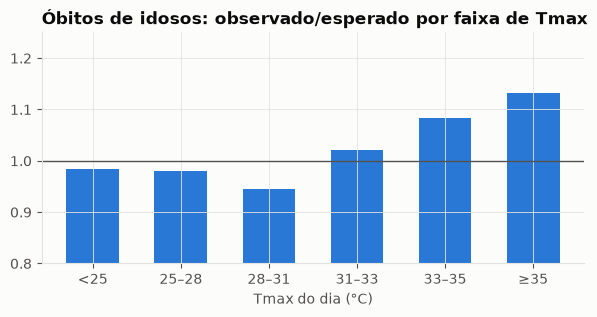

In [7]:
sm = saude[saude.recorte.eq("santa_maria")].merge(clima[["data","tmax"]], on="data")
sm = sm[sm.data.between("2020-01-01","2024-12-31") & sm.data.dt.month.isin([11,12,1,2,3])].copy()
sm["estrato"] = sm.data.dt.to_period("M").astype(str) + sm.data.dt.day_of_week.astype(str)
sm["esperado"] = sm.groupby("estrato").obitos_idosos.transform("mean")
sm["faixa"] = pd.cut(sm.tmax, [0, 25, 28, 31, 33, 35, 45], labels=["<25", "25–28", "28–31", "31–33", "33–35", "≥35"])
dr = sm.groupby("faixa", observed=True).agg(dias=("data","size"), obs=("obitos_idosos","sum"), esp=("esperado","sum"))
dr["razao"] = dr.obs / dr.esp
display(dr)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(dr.index.astype(str), dr.razao, color=figuras.AZUL, width=.6)
ax.axhline(1, color=figuras.TEXTO_2, lw=1); ax.set_ylim(.8, 1.25)
ax.set_title("Óbitos de idosos: observado/esperado por faixa de Tmax"); ax.set_xlabel("Tmax do dia (°C)")

## 3. Onde o calor e os idosos se encontram

### 3.1 Temperatura de superfície (Landsat) e vegetação (NDVI)

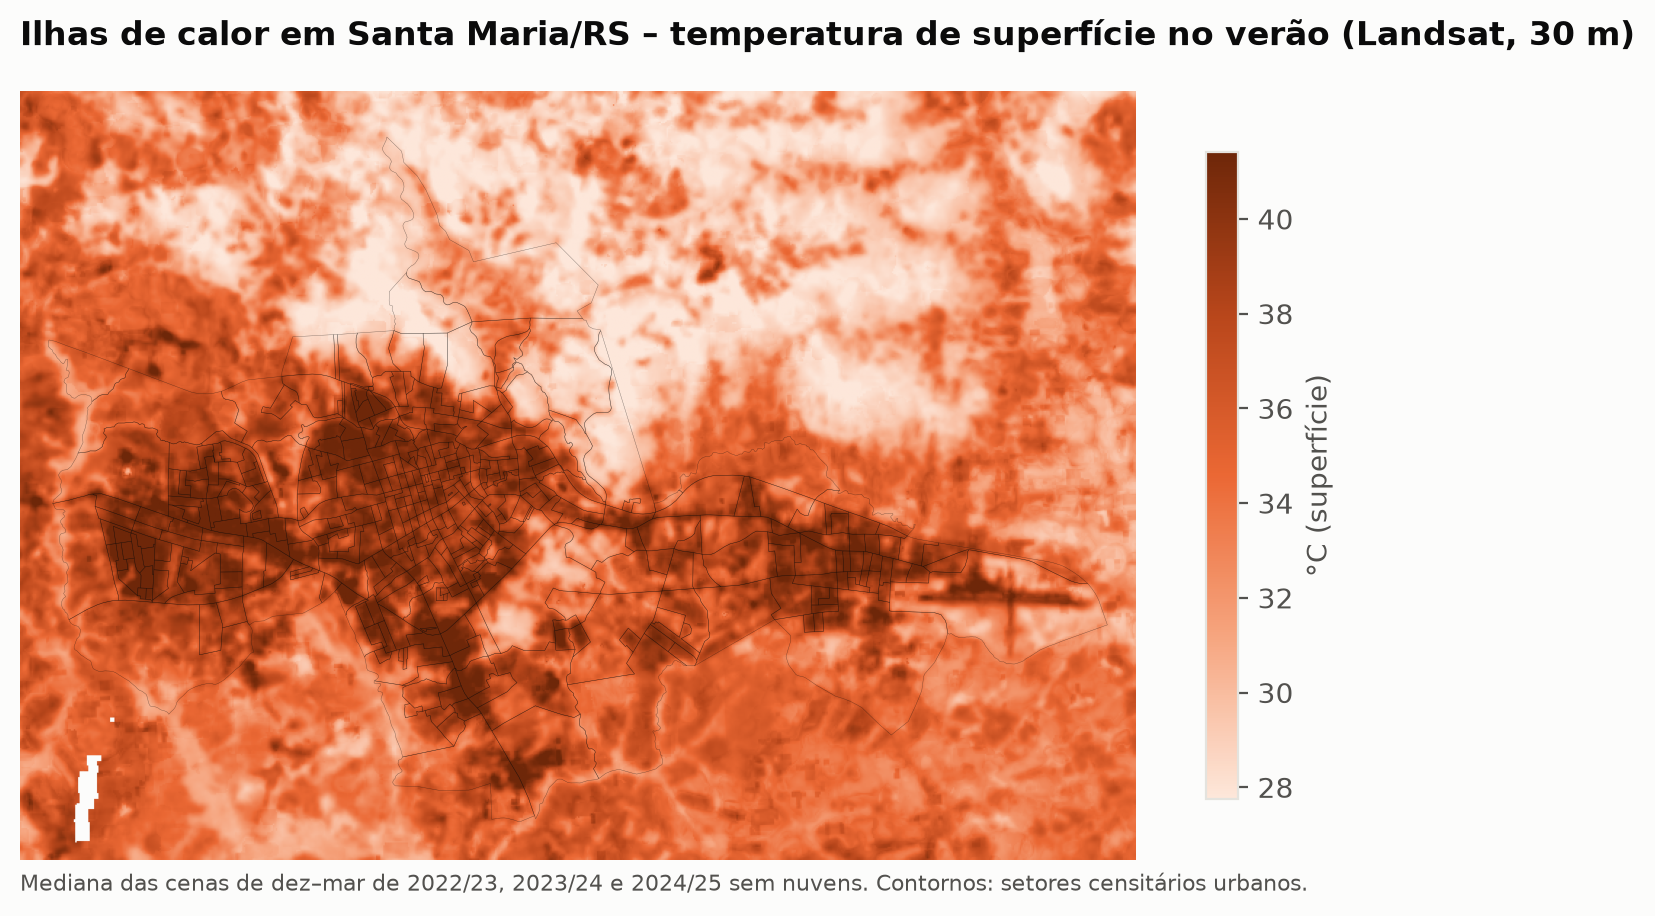

In [8]:
Image(C.DOCS_IMG / "mapa_lst_santa_maria.png")

Text(0.0, 1.0, 'Mais verde, mais fresco (r = -0.78; -1.33 °C a cada +0,1 de NDVI)')

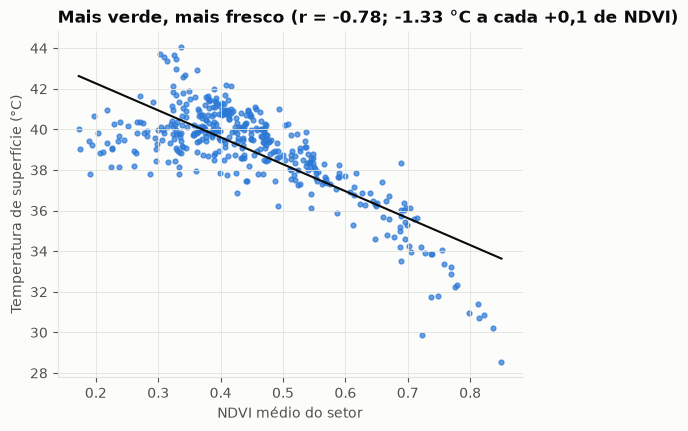

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(setores.ndvi_media, setores.lst_media, s=12, color=figuras.AZUL, alpha=.7)
b, a = np.polyfit(setores.ndvi_media, setores.lst_media, 1)
x = np.linspace(setores.ndvi_media.min(), setores.ndvi_media.max(), 50)
ax.plot(x, a + b * x, color=figuras.TEXTO, lw=1.5)
r = setores[["ndvi_media","lst_media"]].corr().iloc[0, 1]
ax.set_xlabel("NDVI médio do setor"); ax.set_ylabel("Temperatura de superfície (°C)")
ax.set_title(f"Mais verde, mais fresco (r = {r:.2f}; {b/10:+.2f} °C a cada +0,1 de NDVI)")

### 3.2 Bairros mais quentes e mais frescos

In [10]:
bairros = setores.groupby("bairro").agg(setores=("bairro","size"), idosos=("idosos_60_mais","sum"),
                                        moradores=("moradores","sum"), lst=("lst_media","mean"), ndvi=("ndvi_media","mean"))
bairros["pct_idosos"] = 100 * bairros.idosos / bairros.moradores
bairros = bairros.sort_values("lst", ascending=False)
display(pd.concat([bairros.head(8), bairros.tail(5)]).round(2))

,setores,idosos,moradores,lst,ndvi,pct_idosos
bairro,,,,,,
Tancredo Neves,13,2291.0,9494.0,42.09,0.40,24.13
Divina Providência,1,196.0,1176.0,41.68,0.41,16.67
Salgado Filho,12,1524.0,9729.0,40.85,0.42,15.66
Juscelino Kubitschek,17,2604.0,12180.0,40.76,0.41,21.38
Uglione,3,361.0,1851.0,40.60,0.41,19.50
Dom Antônio Reis,2,426.0,1911.0,40.28,0.43,22.29
Pinheiro Machado,16,1973.0,13935.0,40.12,0.44,14.16
Carolina,5,597.0,2616.0,40.04,0.48,22.82
Itararé,10,1464.0,5865.0,36.00,0.59,24.96


salvo docs/img/mapas_setores.png


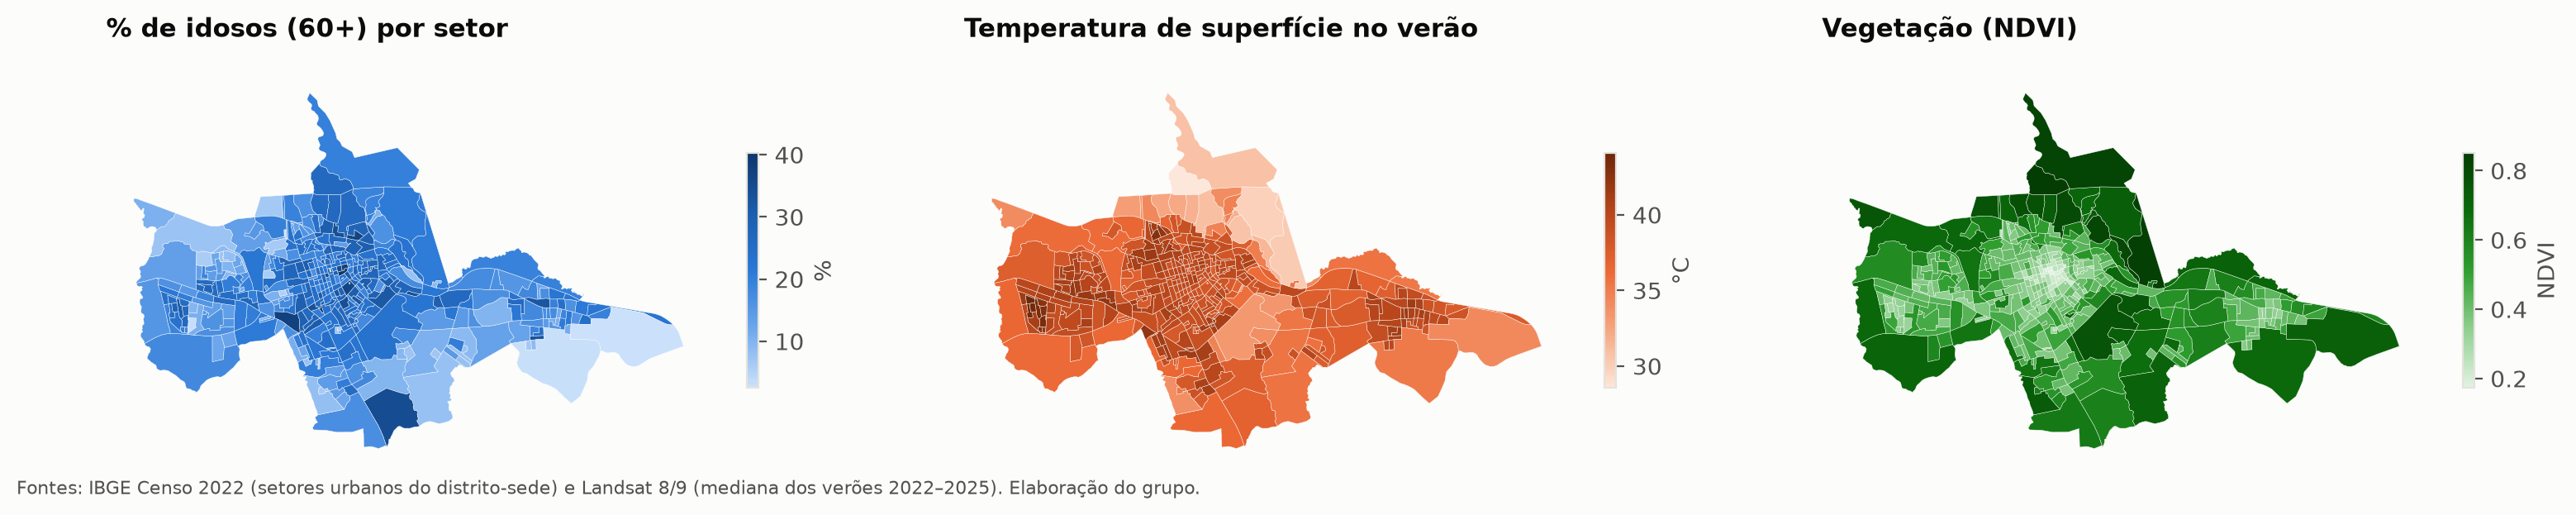

In [11]:
figuras.mapas_setores()
Image(C.DOCS_IMG / "mapas_setores.png")

## 4. Conclusões da análise exploratória

1. **O calor extremo é crescente e real:** a média de dias com máxima ≥ 35 °C triplicou entre 1991–2000 e 2016–2025.
2. **O calor está associado a mortes de idosos:** cerca de +14% de óbitos de pessoas com 60 anos ou mais nos dias ≥ 35 °C, sem aumento de internações. O risco aparece *antes* de chegar ao hospital, o que justifica um **sistema de alerta preventivo**.
3. **A desigualdade intraurbana é grande:** cerca de 9 °C de diferença na superfície entre bairros, explicada em boa parte pela vegetação (r ≈ −0,78). Isso orienta **onde plantar** e **onde priorizar alertas**.

Próximo caderno: `02_modelos_ia.ipynb` (CNN de uso do solo, índice de risco/clusterização e recomendação).